# AN8 — Validated Metrics and Curated Reporting Tables

**Execution status: INITIAL EXTRACTION EXECUTED; EXTENDED ANALYTICAL INVESTIGATION PREPARED — AN8.30–AN8.36 NOT YET EXECUTED.** This notebook records the analytical process, retained execution evidence, interpretation, and validation decisions. Execute documented cells in sequence; do not use **Run All**.

The initial controlled batch has saved evidence for AN8.01–AN8.04, AN8.10–AN8.12, and AN8.20. Additional SQL investigations AN8.30–AN8.36 extend the descriptive metric, quality, exposure, assessment, and segmentation scope. Their outputs must be reviewed before AN8 can close.

## Analytical architecture

1. Run canonical read-only SQL extracts with explicit validation gates.
2. Retain complete result sets as local CSV files with a non-sensitive manifest under outputs/an8/extracts/.
3. Review, reconcile, and interpret SQL outputs before approving metrics.
4. Use Python for result validation and visualization, not to silently replace SQL aggregations.
5. Only after separate explicit approval, load validated extracts into curated PostgreSQL reporting tables.

The validated cohort grain is **student–presentation**, identified by code_module + code_presentation + id_student. final_result is retrospective context, not an approved predictive feature, causal measure, KPI, threshold, or composite score. Curated tables remain a separate persistent-database change requiring explicit approval.

## 0. Environment and helper imports

The helper imports completed successfully. The project root was located, and the AN8 runner imported without error. This cell does not connect to PostgreSQL.

In [1]:
from pathlib import Path
import sys
import pandas as pd

# Locate the repository root from the current Jupyter directory.
PROJECT_ROOT = next(
    (
        parent
        for parent in (Path.cwd(), *Path.cwd().parents)
        if (parent / "scripts" / "run_an8.py").is_file()
        and (parent / "src" / "analytics" / "db.py").is_file()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate the OULAD repository root. "
        "Start Jupyter from the repository or one of its subdirectories."
    )

# Make the repository root available to Python imports.
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from scripts.run_an8 import preflight, run_one, export_results

AN8_EXPORT_DIR = PROJECT_ROOT / "outputs" / "an8" / "extracts"
query_results = {}

print("Project root:", PROJECT_ROOT)
print("AN8 runner import: PASS")

Project root: G:\OULAD-EdTech-Learning-Analytics-starter\OULAD-EdTech-Learning-Analytics
AN8 runner import: PASS


## 1. Database identity and read-only preflight

**Execution result: PASS.** The saved preflight output confirms database `oulad_analytics`, user `postgres`, schema `public`, PostgreSQL 18.6, `transaction_read_only=on`, and `default_transaction_read_only=on`. The configured statement and lock timeouts were `2min` and `5s`. This establishes the intended read-only connection context for the executed batch; it does not validate queries that have not yet run.

In [2]:
preflight_result = preflight()


AN8 — read-only database preflight
  database_name database_user current_schema server_version transaction_read_only default_transaction_read_only statement_timeout lock_timeout
oulad_analytics      postgres         public           18.6                    on                            on              2min           5s
database_name: PASS
transaction_read_only: PASS
default_transaction_read_only: PASS


## 2. AN8.01 — Source relation inventory

**Execution result: PASS.** All seven expected STAGING relations were found. The query reads PostgreSQL catalog statistics rather than counting every row. Its `estimated_rows` values are planner estimates, not exact table counts. In particular, the estimate of zero for `staging.courses` does not establish that the table is empty. The `last_analyze` and `last_autoanalyze` fields were NULL for all seven relations, so the estimates should not be used as exact population figures.

In [3]:
an801 = run_one("AN8.01")
query_results["AN8.01"] = an801
an801["data"]


AN8.01 — source readiness gate
all_expected_relations_returned: PASS
all_expected_relations_exist: PASS
AN8.01: 0.269 s; 1 result set(s); 7 displayed rows; no truncation


,source_relation,relation_exists,estimated_rows,last_analyze,last_autoanalyze
0,staging.assessments,True,206,None,None
1,staging.courses,True,0,None,None
2,staging.student_assessment,True,173912,None,None
3,staging.student_info,True,32593,None,None
4,staging.student_registration,True,32593,None,None
5,staging.student_vle,True,10654140,None,None
6,staging.vle,True,6364,None,None


## 3. AN8.02 — Student-presentation grain and key-set gate

**Execution result: PASS — all six checks.** Both `staging.student_info` and `staging.student_registration` returned 32,593 rows and 32,593 distinct composite keys. Each source had zero duplicate key groups and zero rows with NULL key components. The bidirectional key-set comparison returned zero differences.

The validated join key is `code_module + code_presentation + id_student`. The analytical grain is therefore **one student–presentation**, not one person: a student may appear in more than one module or presentation. This gate validates the relationship between these two sources only; it does not establish key integrity for every other STAGING relation.

In [4]:
an802 = run_one("AN8.02")
query_results["AN8.02"] = an802
an802["data"]


AN8.02 — student-presentation grain gate
    check_type            check_name  source_rows  distinct_keys  duplicate_key_groups  null_key_rows  key_count
KEY_DIFFERENCE INFO_NOT_REGISTRATION          NaN            NaN                   NaN            NaN        0.0
KEY_DIFFERENCE REGISTRATION_NOT_INFO          NaN            NaN                   NaN            NaN        0.0
  SOURCE_GRAIN          student_info      32593.0        32593.0                   0.0            0.0        NaN
  SOURCE_GRAIN  student_registration      32593.0        32593.0                   0.0            0.0        NaN
no_duplicate_student_info_keys: PASS
no_duplicate_registration_keys: PASS
student_info_rows_equal_distinct_keys: PASS
registration_rows_equal_distinct_keys: PASS
no_null_key_rows: PASS
no_key_set_differences: PASS
AN8.02: 0.426 s; 1 result set(s); 4 displayed rows; no truncation


,check_type,check_name,source_rows,distinct_keys,duplicate_key_groups,null_key_rows,key_count
0,KEY_DIFFERENCE,INFO_NOT_REGISTRATION,NaN,NaN,NaN,NaN,0.0
1,KEY_DIFFERENCE,REGISTRATION_NOT_INFO,NaN,NaN,NaN,NaN,0.0
2,SOURCE_GRAIN,student_info,32593.0,32593.0,0.0,0.0,NaN
3,SOURCE_GRAIN,student_registration,32593.0,32593.0,0.0,0.0,NaN


## 4. AN8.03 — Outcome denominator profile

**Execution result: PASS.** The four retrospective `final_result` categories reconcile to 32,593 student–presentation rows, and all 32,593 rows have a matching registration record. The result profile is suitable for describing the validated cohort at student–presentation grain.

The `distinct_student_ids_in_category` field counts unique student IDs separately within each outcome category. These category-specific counts are not mutually exclusive across presentations and must not be added to infer the number of unique people. Because `final_result` is a retrospective outcome, it must not be treated as information available during a student's active study period or as evidence of causation or predictive performance.

In [5]:
an803 = run_one("AN8.03")
query_results["AN8.03"] = an803
an803["data"]

\nAN8.03 — outcome denominator reconciliation
outcome_denominator_matches_student_info: PASS
registration_matches_equal_validated_cohort: PASS
AN8.03: 0.066 s; 1 result set(s); 4 displayed rows; no truncation


,final_result,student_presentation_rows,registration_matched_rows,distinct_student_ids_in_category
0,Distinction,3024,3024,2903
1,Fail,7052,7052,6810
2,Pass,12361,12361,11881
3,Withdrawn,10156,10156,9155


### Outcome distribution — student–presentation records

The table above establishes the category counts and denominator reconciliation. The chart below expresses the same validated counts as both record totals and shares of the 32,593 student–presentation records. It is generated from the saved AN8.03 result in memory; it does not issue another SQL query or reconnect to PostgreSQL.

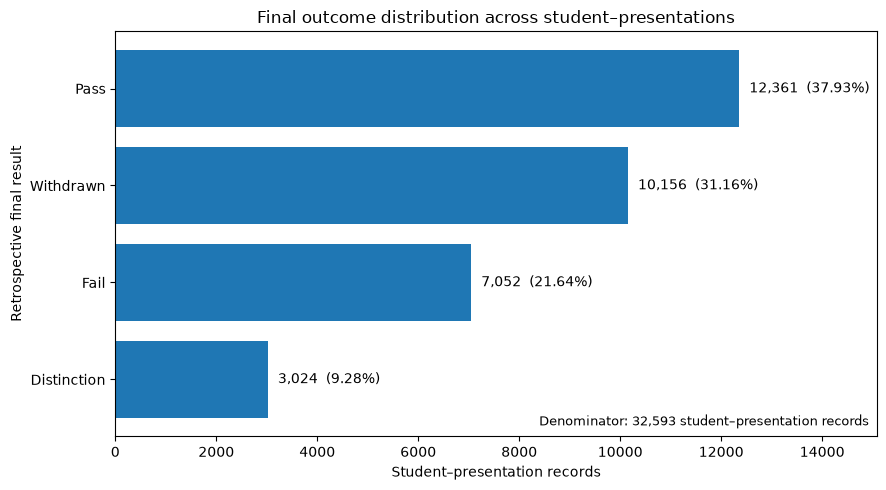

In [6]:
import matplotlib.pyplot as plt

outcome_plot = an803["data"][[
    "final_result",
    "student_presentation_rows",
    "registration_matched_rows",
]].copy()

outcome_plot["share_pct"] = (
    outcome_plot["student_presentation_rows"]
    / outcome_plot["student_presentation_rows"].sum()
    * 100
)
outcome_plot = outcome_plot.sort_values(
    "student_presentation_rows", ascending=True
)

denominator = int(outcome_plot["student_presentation_rows"].sum())
assert denominator == 32593
assert (
    outcome_plot["student_presentation_rows"]
    == outcome_plot["registration_matched_rows"]
).all()

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(
    outcome_plot["final_result"],
    outcome_plot["student_presentation_rows"],
)
ax.set_title("Final outcome distribution across student–presentations")
ax.set_xlabel("Student–presentation records")
ax.set_ylabel("Retrospective final result")
ax.set_xlim(0, outcome_plot["student_presentation_rows"].max() * 1.22)

for bar, count, share in zip(
    bars,
    outcome_plot["student_presentation_rows"],
    outcome_plot["share_pct"],
):
    ax.text(
        bar.get_width() + denominator * 0.006,
        bar.get_y() + bar.get_height() / 2,
        f"{int(count):,}  ({share:.2f}%)",
        va="center",
    )

ax.text(
    0.99, 0.02,
    f"Denominator: {denominator:,} student–presentation records",
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=9,
)
fig.tight_layout()
plt.show()

### Interpretation of the outcome distribution

The distribution is led by **Pass** (12,361 records; 37.93%), followed by **Withdrawn** (10,156; 31.16%), **Fail** (7,052; 21.64%), and **Distinction** (3,024; 9.28%). The chart makes the relative size of these four categories easier to compare while preserving the exact student–presentation denominator.

The withdrawal category represents nearly one third of the records, so it should remain visible in later descriptive analysis rather than being silently combined with failure or excluded from the cohort. This distribution alone does not explain why students withdrew, establish when withdrawal occurred, or measure engagement. Those questions require the registration-timing and activity evidence planned in subsequent AN8 sections.

The denominator is student–presentation records, not unique individuals. The chart is a retrospective cohort description and must not be interpreted as a causal comparison, a live-risk indicator, or a model-performance result.

## 5. AN8.04 — Course and assessment context

AN8.04 returns **two result sets**. The runner checks truncation independently for each result set. Due dates and weights do not establish score or feedback availability.

In [7]:
an804 = run_one("AN8.04")
query_results["AN8.04"] = an804
for item in an804["result_sets"]:
    display(item["data"])


AN8.04 — course and assessment context gate
course_context_nonempty: PASS
course_keys_non_null: PASS
course_keys_unique: PASS
course_lengths_non_null: PASS
assessment_context_keys_unique: PASS
assessment_context_covers_course_keys: PASS
AN8.04: 0.028 s; 2 result set(s); 44 displayed rows; no truncation


,code_module,code_presentation,module_presentation_length
0,AAA,2013J,268
1,AAA,2014J,269
2,BBB,2013B,240
3,BBB,2013J,268
4,BBB,2014B,234
5,BBB,2014J,262
6,CCC,2014B,241
7,CCC,2014J,269
8,DDD,2013B,240
9,DDD,2013J,261


,code_module,code_presentation,assessment_count,missing_due_dates,total_weight
0,AAA,2013J,6,1,200
1,AAA,2014J,6,1,200
2,BBB,2013B,12,1,200
3,BBB,2013J,12,1,200
4,BBB,2014B,12,1,200
5,BBB,2014J,6,1,200
6,CCC,2014B,10,2,300
7,CCC,2014J,10,2,300
8,DDD,2013B,14,0,200.0
9,DDD,2013J,7,0,200.0


## 6. AN8.10–AN8.12 — Lightweight descriptive context

Run these only after the grain gate passes. Each query has its own result set and must be reviewed before the activity extract. These are descriptive context, not approved KPIs.

In [8]:
for query_id in ("AN8.10", "AN8.11", "AN8.12"):
    query_results[query_id] = run_one(query_id)
    print(query_id)
    display(query_results[query_id]["data"])

AN8.10: 0.015 s; 1 result set(s); 4 displayed rows; no truncation
AN8.10


,registration_timing,registrations
0,AFTER_START,234
1,BEFORE_START,32312
2,MISSING,45
3,ON_START,2


AN8.11: 0.06 s; 1 result set(s); 6 displayed rows; no truncation
AN8.11


,final_result,unregistration_state,student_presentations
0,Distinction,NO_UNREGISTRATION_DATE,3024
1,Fail,HAS_UNREGISTRATION_DATE,9
2,Fail,NO_UNREGISTRATION_DATE,7043
3,Pass,NO_UNREGISTRATION_DATE,12361
4,Withdrawn,HAS_UNREGISTRATION_DATE,10063
5,Withdrawn,NO_UNREGISTRATION_DATE,93


AN8.12: 0.12 s; 1 result set(s); 3 displayed rows; no truncation
AN8.12


,score_state,student_assessment_rows
0,NONZERO_SCORE,173410
1,NULL_SCORE,173
2,OBSERVED_ZERO,329


## 7. AN8.20 — Consolidated activity extract (single high-cost scan)

**Run this query once, alone.** It consolidates the activity measures that were previously spread across AN8.20–AN8.23 into one pass over `staging.student_vle`.

The output contains one row per registered student-presentation, including:
- R0 source activity-row and click totals;
- pre-course, in-course, and post-course row/click partitions;
- in-course active days and resource breadth;
- post-registration active days, resource breadth, exposure days, and active-day rate.

The numerator of the post-registration active-day rate is restricted to dates from `max(date_registration, 0)` through course end. Missing registration dates remain NULL for post-registration measures. The extract does not truncate activity at unregistration.

The runner checks the output row count and composite-key uniqueness against the validated AN8.02 cohort. Stop if the gate fails.

In [9]:
activity_extract = run_one("AN8.20")
query_results["AN8.20"] = activity_extract
activity_frame = activity_extract["data"]
print(activity_frame.shape)
display(activity_frame.head())


AN8.20 — student-presentation extract gate
row_count_matches_validated_cohort: PASS
unique_student_presentation_key: PASS
non_null_student_presentation_key: PASS
AN8.20: 85.582 s; 1 result set(s); 32593 displayed rows; no truncation
(32593, 37)


,code_module,code_presentation,id_student,date_registration,course_length,exposure_start,post_registration_exposure_days,all_observed_activity_rows,all_observed_recorded_clicks,pre_course_activity_rows,...,matched_registered_recorded_clicks,unmatched_recorded_clicks,all_source_in_course_activity_rows,all_source_pre_course_activity_rows,all_source_post_course_activity_rows,all_source_no_course_window_activity_rows,all_source_pre_course_recorded_clicks,all_source_in_course_recorded_clicks,all_source_post_course_recorded_clicks,all_source_no_course_window_recorded_clicks
0,AAA,2013J,11391,-159.0,268,0.0,269.0,196,934,11,...,39605099,0,9966292,688988,0,0,2147947,37457152,0,0
1,AAA,2013J,28400,-53.0,268,0.0,269.0,430,1435,55,...,39605099,0,9966292,688988,0,0,2147947,37457152,0,0
2,AAA,2013J,30268,-92.0,268,0.0,269.0,76,281,34,...,39605099,0,9966292,688988,0,0,2147947,37457152,0,0
3,AAA,2013J,31604,-52.0,268,0.0,269.0,663,2158,38,...,39605099,0,9966292,688988,0,0,2147947,37457152,0,0
4,AAA,2013J,32885,-176.0,268,0.0,269.0,352,1034,66,...,39605099,0,9966292,688988,0,0,2147947,37457152,0,0


## 11. Curated reporting tables — approval gate

The intended downstream design is to load the validated retained extracts into a small set of persistent, documented reporting tables (for example, a student-presentation activity fact and course/assessment dimensions), then build all charts and Power BI datasets from those tables.

**No table, view, materialized view, index, schema, or DDL is created here.** Before deployment, the project owner must review and explicitly approve:
- table names, schemas, columns, keys, and data types;
- CSV-to-table load method and reconciliation checks;
- refresh/replacement policy and provenance manifest;
- retention, access, and privacy controls;
- exact row/key/count/denominator acceptance criteria.

After approval, prepare a separate DDL/load work order. It must load the already validated extracts, not rescan `staging.student_vle` to recreate chart inputs.

## 14. AN8.30–AN8.36 — Extended analytical investigation

The initial execution established source readiness, student–presentation grain, outcome denominators, course context, and a complete R0 activity extract. It did not yet provide metric distributions, scenario-impact profiles, exposure sensitivity, assessment coverage, or profile segmentation. The following canonical SQL investigations extend that scope.

**Execution policy:** run each high-cost query individually after the existing AN0.01 and AN8.02 gates pass. Do not use Run All. SQL remains the source of analytical aggregations; Python receives result sets for validation and visualization.

| Query | Scope | Cost |
|---|---|---|
| AN8.30 | R0/R1/R2 scenario totals, source-quality and reference-integrity diagnostics | High |
| AN8.31 | Zero-inclusive activity-row, click, active-day, and resource-breadth distributions | High |
| AN8.32 | Registration timing and available exposure days | Low |
| AN8.33 | Candidate metric definitions and approval status | Very low |
| AN8.34 | Activity distributions by outcome within each presentation | High |
| AN8.35 | Assessment participation and score-state coverage | Moderate |
| AN8.36 | Outcome segments by student-profile dimensions | Low |

AN8.30 complements rather than replaces AN5 scenario sensitivity. AN8.34 uses final_result only as retrospective descriptive grouping. AN8.35 separates no submission from a recorded NULL score. AN8.36 is descriptive, not a fairness assessment.

In [ ]:
an830 = run_one("AN8.30")
query_results["AN8.30"] = an830
for item in an830["result_sets"]:
    display(item["data"])

### AN8.31 — Zero-inclusive registered activity distributions

This is a separate high-cost SQL aggregation. The registered student–presentation population remains the denominator, including zero-activity registrations. Source-row and click measures remain sensitive to repeated student_vle records; active days and resource breadth are distinct-value measures.

In [ ]:
an831 = run_one("AN8.31")
query_results["AN8.31"] = an831
display(an831["data"])

### AN8.32 — Registration and exposure profile

Exposure is the inclusive number of course days from the later of registration day and day zero through the course end. Missing registration dates remain unknown; registrations after course end have zero available course exposure. This is opportunity-to-observe, not attendance.

In [ ]:
an832 = run_one("AN8.32")
query_results["AN8.32"] = an832
display(an832["data"])

### AN8.33 — Candidate metric register

This query documents operational definitions, grain, denominator, limitations, and approval status. It does not approve a production KPI.

In [ ]:
an833 = run_one("AN8.33")
query_results["AN8.33"] = an833
display(an833["data"])

### AN8.34 — Activity by retrospective outcome and presentation

High-cost descriptive SQL aggregation. Each presentation is reported separately to avoid pooling structurally different cohorts. final_result is used only to describe retrospective associations; it is not an early-warning predictor or causal explanation.

In [ ]:
an834 = run_one("AN8.34")
query_results["AN8.34"] = an834
display(an834["data"])

### AN8.35 — Assessment participation and score-state coverage

The output distinguishes no submission, NULL score, observed zero, and nonzero score. Assessment opportunities repeat across assessments, so assessment-level denominators are not additive counts of unique students.

In [ ]:
an835 = run_one("AN8.35")
query_results["AN8.35"] = an835
display(an835["data"])

### AN8.36 — Student-profile outcome segments

This profile is grouped by presentation and explicitly retains missing IMD bands. Small segments require review and possible suppression before publication. Results are descriptive associations, not causal effects or a fairness assessment.

In [ ]:
an836 = run_one("AN8.36")
query_results["AN8.36"] = an836
display(an836["data"])

## 8. Persist the reviewed extract locally

After inspecting the complete AN8.20 output and its gate, export the retained DataFrames to CSV with a JSON manifest. This is local file output only; it does not create PostgreSQL objects.

Do not export if a result set is truncated or the cohort gate failed.

In [10]:
manifest_path = export_results(query_results, AN8_EXPORT_DIR)
manifest_path

AN8 exports and manifest saved to: G:\OULAD-EdTech-Learning-Analytics-starter\OULAD-EdTech-Learning-Analytics\outputs\an8\extracts


WindowsPath('G:/OULAD-EdTech-Learning-Analytics-starter/OULAD-EdTech-Learning-Analytics/outputs/an8/extracts/an8_execution_manifest.json')

## 9. Python-only reconciliation from retained extracts

All calculations in this section use in-memory results or exported CSVs. No SQL or database connection is issued. Reconcile the course-relative row totals and registered population before creating any visualization.

In [11]:
# Load the persisted AN8.20 extract; this cell performs no database connection.
activity = pd.read_csv(AN8_EXPORT_DIR / "AN8_20_result_01.csv")

# Reuse the validated registration denominator retained by AN8.02.
registration_rows = query_results["AN8.02"]["result_sets"][0]["data"]
registration_denominator = int(
    registration_rows.loc[
        registration_rows["check_type"].eq("SOURCE_GRAIN")
        & registration_rows["check_name"].eq("student_registration"),
        "source_rows",
    ].iloc[0]
)

registered_rows = len(activity)
source_total = int(activity["total_source_activity_rows"].iloc[0])
matched_source_rows = int(activity["matched_registered_activity_rows"].iloc[0])
unmatched_source_rows = int(activity["unmatched_activity_rows"].iloc[0])
source_clicks = float(activity["total_source_recorded_clicks"].iloc[0])
matched_clicks = float(activity["matched_registered_recorded_clicks"].iloc[0])
unmatched_clicks = float(activity["unmatched_recorded_clicks"].iloc[0])

matched_partition_columns = [
    "pre_course_activity_rows",
    "in_course_activity_rows",
    "post_course_activity_rows",
    "no_course_window_activity_rows",
]
source_partition_columns = [
    "all_source_pre_course_activity_rows",
    "all_source_in_course_activity_rows",
    "all_source_post_course_activity_rows",
    "all_source_no_course_window_activity_rows",
]
matched_click_columns = [
    "pre_course_recorded_clicks",
    "in_course_recorded_clicks",
    "post_course_recorded_clicks",
    "no_course_window_recorded_clicks",
]
source_click_columns = [
    "all_source_pre_course_recorded_clicks",
    "all_source_in_course_recorded_clicks",
    "all_source_post_course_recorded_clicks",
    "all_source_no_course_window_recorded_clicks",
]

matched_partition_total = int(activity[matched_partition_columns].sum().sum())
source_partition_total = int(activity[source_partition_columns].iloc[0].sum())
matched_click_partition_total = float(activity[matched_click_columns].sum().sum())
source_click_partition_total = float(activity[source_click_columns].iloc[0].sum())

exposed = activity["post_registration_exposure_days"].notna()
student_presentation_key = ["code_module", "code_presentation", "id_student"]

checks = {
    "row_count_matches_an802_registration_denominator": (
        registered_rows == registration_denominator
    ),
    "non_null_student_presentation_key": (
        not activity[student_presentation_key].isna().any().any()
    ),
    "one_row_per_registered_student_presentation": (
        registered_rows
        == len(activity[student_presentation_key].drop_duplicates())
    ),
    "registered_activity_rows_reconcile": (
        int(activity["all_observed_activity_rows"].sum()) == matched_source_rows
    ),
    "registered_temporal_partition_reconciles": (
        matched_partition_total == matched_source_rows
    ),
    "all_source_temporal_partition_reconciles": (
        source_partition_total == source_total
    ),
    "source_rows_equal_matched_plus_unmatched": (
        source_total == matched_source_rows + unmatched_source_rows
    ),
    "clicks_equal_matched_plus_unmatched": (
        abs(source_clicks - matched_clicks - unmatched_clicks) < 1e-9
    ),
    "registered_click_partition_reconciles": (
        abs(matched_click_partition_total - matched_clicks) < 1e-9
    ),
    "source_click_partition_reconciles": (
        abs(source_click_partition_total - source_clicks) < 1e-9
    ),
    "active_days_are_nonnegative": (
        bool((activity["in_course_active_days"] >= 0).all())
    ),
    "active_days_do_not_exceed_exposure": (
        bool(
            (
                activity.loc[exposed, "post_registration_active_days"] >= 0
            ).all()
            and (
                activity.loc[exposed, "post_registration_active_days"]
                <= activity.loc[exposed, "post_registration_exposure_days"]
            ).all()
        )
    ),
}

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'FAIL'}")

if not all(checks.values()):
    failed_checks = [name for name, passed in checks.items() if not passed]
    raise RuntimeError(
        "AN8.20 reconciliation failed; stop before visualizations or mart design. "
        f"Failed checks: {failed_checks}"
    )

reconciliation_summary = pd.DataFrame(
    [
        {
            "registered_student_presentations": registered_rows,
            "registration_denominator": registration_denominator,
            "source_activity_rows": source_total,
            "source_recorded_clicks": source_clicks,
            "matched_registered_recorded_clicks": matched_clicks,
            "unmatched_recorded_clicks": unmatched_clicks,
            "matched_registered_activity_rows": matched_source_rows,
            "unmatched_activity_rows": unmatched_source_rows,
            "registered_temporal_partition_rows": matched_partition_total,
            "all_source_temporal_partition_rows": source_partition_total,
        }
    ]
)
display(reconciliation_summary)

row_count_matches_an802_registration_denominator: PASS
non_null_student_presentation_key: PASS
one_row_per_registered_student_presentation: PASS
registered_activity_rows_reconcile: PASS
registered_temporal_partition_reconciles: PASS
all_source_temporal_partition_reconciles: PASS
source_rows_equal_matched_plus_unmatched: PASS
clicks_equal_matched_plus_unmatched: PASS
registered_click_partition_reconciles: PASS
source_click_partition_reconciles: PASS
active_days_are_nonnegative: PASS
active_days_do_not_exceed_exposure: PASS


,registered_student_presentations,registration_denominator,source_activity_rows,source_recorded_clicks,matched_registered_recorded_clicks,unmatched_recorded_clicks,matched_registered_activity_rows,unmatched_activity_rows,registered_temporal_partition_rows,all_source_temporal_partition_rows
0,32593,32593,10655280,39605099.0,39605099.0,0.0,10655280,0,10655280,10655280


## 10. Visualization source contract

Every chart must have its own preceding Markdown explanation. Visualization cells read only the curated reporting tables or retained files under `outputs/an8/`. They must not call `run_one`, `run_batch`, `run_query`, or connect to PostgreSQL.

Illustrative starter below is intentionally Python-only and uses the retained extract.

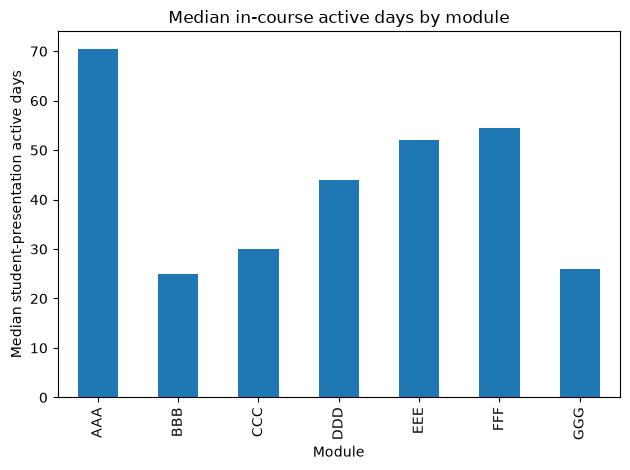

In [12]:
import matplotlib.pyplot as plt

plot_data = activity.groupby("code_module", as_index=False)["in_course_active_days"].median()
ax = plot_data.plot(kind="bar", x="code_module", y="in_course_active_days", legend=False)
ax.set_title("Median in-course active days by module")
ax.set_xlabel("Module")
ax.set_ylabel("Median student-presentation active days")
plt.tight_layout()

## 15. Extended analytical review gate

Do not approve a metric or proceed to Power BI solely because a query executed. Review complete result sets and truncation flags, denominators, zero-inclusive distributions, missing/unknown states, R0/R1/R2 sensitivity, exposure definitions, assessment score states, presentation-specific comparisons, and small-cell limitations.

The SQL extension is prepared but remains **unexecuted** until local execution and review. No database tables, views, indexes, schemas, or other persistent objects are created.

## 16. Current status and next phase gates

**AN8 initial extraction:** executed locally; saved outputs document read-only preflight, source and cohort gates, course/assessment context, registration timing, withdrawal-date reconciliation, score missingness, consolidated R0 activity extract, and Python reconciliation.

**AN8 extended analysis:** SQL files and Notebook 10 cells AN8.30–AN8.36 are prepared on this branch; they have not been executed or validated against the local database.

**AN8 approval status:** no production KPI, curated reporting table, or Power BI dataset is approved. AN8 remains open until extended query outputs are reviewed, metric definitions and denominators are accepted, and the final reporting contract is agreed.

**Data preservation:** RAW, QUALITY, and STAGING are unchanged. The new SQL files are SELECT-only. No persistent tables, views, materialized views, indexes, or schemas are created.

AN9 Power BI remains blocked until AN8 metrics and the reporting contract are validated. AN10 final evidence-based reporting follows the approved reporting outputs.